<div style="background:linear-gradient(120deg,#0a2a5c,#1c5aa6);color:#fff;padding:22px 26px;border-radius:12px;border-bottom:5px solid #d49a2a;">
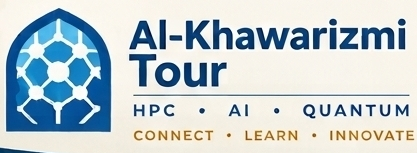
<p style="color:#ffd98e;letter-spacing:.14em;font-size:12px;font-weight:700;margin:12px 0 4px;">AL-KHAWARIZMI TOUR · ONLINE HACKATHON HPC &amp; AI · OCT 3 – NOV 7, 2026 · LECTURE 2 NOTEBOOK</p>
<h1 style="color:#fff;margin:4px 0 6px;border:none;">Introduction to AI Methods — Beijing Air Quality · Hands-on &amp; Week-2 Team Challenge</h1>
<p style="color:#e6eef8;margin:0;">Part A: guided demos of supervised, unsupervised and neural-network methods (slide references in each heading) · Part B: the week-long <b>AI Methods Shoot-out</b></p>
<p style="color:#ffd98e;margin:10px 0 0;font-style:italic;">Connect · Learn · Innovate — Instructor: Dr. Rafik Borji</p></div>

## How to use this notebook

| Part | When | What |
|---|---|---|
| **A · Guided demos** (A1–A8) | during the 2-hour lecture | one demo per family of methods, all on the same data |
| **B · Team challenge** (Tasks 1–6 + ★ bonus) | the whole week | fill in the `# TODO` cells and write the model card with your conclusions |

**Input:** your cleaned Week-1 training years `beijing_clean_team<N>.csv.gz`. If it is not found, the raw UCI training years are used (real gaps only). The **test year** (1 Mar 2016 – 28 Feb 2017) always comes from the untouched UCI data.

**Running tasks**
* **Virtual PM2.5 sensor** — regression of PM2.5 from gases, weather, time and station (no PM10).
* **Unhealthy-hour alert** — classify PM2.5 > 75 µg/m³.
* **Pollution regimes** — clustering of daily 24-hour PM2.5 profiles.
* **24-hour-ahead forecast** — PM2.5 at *t* + 24 h from the past.

**Speed:** `STEP = 3` keeps every 3rd hour for the demos (≈ 100k rows). Set `STEP = 1` for final results on a fast machine / HPC node.

## 0 · Setup

In [1]:
TEAM_ID = 1013
SEED = 2000 + TEAM_ID
STEP = 1                      # use every STEP-th hour in demos (1 = all data)

import time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.figsize": (10, 4), "axes.grid": True, "grid.alpha": .3})
rng = np.random.default_rng(SEED)

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.model_selection import TimeSeriesSplit, cross_validate, cross_val_score
from sklearn.metrics import (mean_squared_error, mean_absolute_error, r2_score, precision_score, recall_score,
                             f1_score, roc_auc_score, roc_curve, confusion_matrix)
import sklearn; print("scikit-learn", sklearn.__version__)

scikit-learn 1.9.1


---
# Part A · Guided demos
## A1 · Data, features and the time split  *(slides 2 & 6)*

In [2]:
import io, os, glob, ssl, zipfile, urllib.request

STATIONS = ["Aotizhongxin", "Changping", "Dingling", "Dongsi", "Guanyuan", "Gucheng", "Huairou",
            "Nongzhanguan", "Shunyi", "Tiantan", "Wanliu", "Wanshouxigong"]
WD = ["N", "NNE", "NE", "ENE", "E", "ESE", "SE", "SSE", "S", "SSW", "SW", "WSW", "W", "WNW", "NW", "NNW"]
POLLUTANTS = ["PM2.5", "PM10", "SO2", "NO2", "CO", "O3"]
WEATHER = ["TEMP", "PRES", "DEWP", "RAIN", "WSPM"]
KEY = ["station", "year", "month", "day", "hour"]
URL = "https://archive.ics.uci.edu/static/public/501/beijing+multi+site+air+quality+data.zip"
CACHE = "beijing_air_quality_raw.csv.gz"

def _csvs_from_zip(blob):
    """The UCI archive contains a nested zip with one CSV per station -> read them all."""
    frames = []
    with zipfile.ZipFile(io.BytesIO(blob)) as z:
        for name in z.namelist():
            if name.lower().endswith(".zip"):
                frames += _csvs_from_zip(z.read(name))
            elif name.lower().endswith(".csv") and "PRSA_Data" in os.path.basename(name):
                frames.append(pd.read_csv(io.BytesIO(z.read(name))))
    return frames

def _download(url):
    try:
        return urllib.request.urlopen(url, timeout=180).read()
    except Exception:
        return urllib.request.urlopen(url, timeout=180, context=ssl._create_unverified_context()).read()

def synthetic_beijing(seed=0):
    """Offline stand-in with the same columns, 12 stations, seasonal/diurnal cycles and runs of missing values.
    Used ONLY if neither local files nor the UCI download are available."""
    r = np.random.default_rng(seed)
    t = pd.date_range("2013-03-01 00:00", "2017-02-28 23:00", freq="h")
    n, doy, hr = len(t), t.dayofyear.values, t.hour.values
    season = np.cos(2 * np.pi * (doy - 15) / 365.25)                 # +1 in mid-January (heating season)
    e = r.normal(0, 1, n); z = np.zeros(n)
    for i in range(1, n):                                            # regional stagnation index, AR(1)
        z[i] = 0.985 * z[i - 1] + 0.17 * e[i]
    frames = []
    for k, st in enumerate(STATIONS):
        urb = 1.0 if st in ["Dongsi", "Guanyuan", "Gucheng", "Nongzhanguan", "Tiantan", "Wanshouxigong", "Aotizhongxin", "Wanliu"] else 0.0
        TEMP = 13 - 15 * season + 4 * np.sin(2 * np.pi * (hr - 9) / 24) + r.normal(0, 2, n) - (1 - urb)
        DEWP = TEMP - np.clip(r.gamma(2, 4, n) - 3 * z, 0.5, 35)
        PRES = 1012 + 12 * season + r.normal(0, 3, n)
        WSPM = np.clip(r.gamma(2, 0.9, n) - 0.4 * z, 0, None)
        ang = (np.where(z < 0, 315, 180) + r.normal(0, 50, n)) % 360
        wd = np.array(WD)[np.round(ang / 22.5).astype(int) % 16]
        RAIN = np.where(r.random(n) < 0.03 * (1 - season), r.exponential(1.5, n), 0.0)
        logpm = 3.8 + 0.35 * season + 0.9 * z + 0.15 * urb + 0.2 * np.cos(2 * np.pi * (hr - 22) / 24) - 0.15 * WSPM + r.normal(0, .25, n)
        PM25 = np.clip(np.exp(logpm), 3, 900)
        PM10 = PM25 * (1.15 + r.gamma(2, 0.2, n))
        CO = np.clip(300 + 11 * PM25 * (1 + .3 * season) + r.normal(0, 150, n), 100, None)
        NO2 = np.clip(20 + .35 * PM25 ** .8 + 10 * urb + r.normal(0, 8, n), 2, None)
        SO2 = np.clip(3 + 25 * np.clip(season, 0, None) * np.exp(.5 * z) + r.normal(0, 3, n), 2, None)
        O3 = np.clip(10 + 60 * (1 - season) / 2 * 2 * np.clip(np.sin(2 * np.pi * (hr - 8) / 24), 0, None) - .2 * NO2 + r.normal(0, 10, n), 2, None)
        f = pd.DataFrame({"No": np.arange(1, n + 1), "year": t.year, "month": t.month, "day": t.day, "hour": hr,
                          "PM2.5": PM25, "PM10": PM10, "SO2": SO2, "NO2": NO2, "CO": CO, "O3": O3,
                          "TEMP": TEMP, "PRES": PRES, "DEWP": DEWP, "RAIN": RAIN, "wd": wd, "WSPM": WSPM, "station": st}).round(1)
        for c in POLLUTANTS + WEATHER + ["wd"]:                       # runs of missing values
            for s0 in r.choice(n, 25, replace=False):
                f.loc[s0:s0 + int(r.geometric(0.08)), c] = np.nan
        frames.append(f)
    return frames

def load_beijing():
    local = sorted(glob.glob("**/PRSA_Data_*.csv", recursive=True))
    if local:
        frames = [pd.read_csv(f) for f in local]; src = f"{len(local)} local station files"
    elif os.path.exists(CACHE):
        return pd.read_csv(CACHE)
    else:
        try:
            frames = _csvs_from_zip(_download(URL)); src = "UCI download"
        except Exception as e:
            print("UCI not reachable (", type(e).__name__, ")"); frames = []
        if not frames:
            frames = synthetic_beijing(); src = "SYNTHETIC offline stand-in"
    df = pd.concat(frames, ignore_index=True)
    if src == "UCI download":
        df.to_csv(CACHE, index=False)
    print(f"Loaded {df.shape[0]:,} rows x {df.shape[1]} columns from {src}")
    return df

def add_features(d):
    """Model-ready features: datetime, cyclical time, circular wind direction, dew-point depression."""
    d = d.copy()
    d["datetime"] = pd.to_datetime(d[["year", "month", "day", "hour"]], errors="coerce")
    d["hour_sin"], d["hour_cos"] = np.sin(2 * np.pi * d["hour"] / 24), np.cos(2 * np.pi * d["hour"] / 24)
    d["month_sin"], d["month_cos"] = np.sin(2 * np.pi * d["month"] / 12), np.cos(2 * np.pi * d["month"] / 12)
    d["dow"] = d["datetime"].dt.dayofweek
    ang = d["wd"].map({w: i * 2 * np.pi / 16 for i, w in enumerate(WD)})
    d["wd_sin"], d["wd_cos"] = np.sin(ang), np.cos(ang)
    d["TD_dep"] = d["TEMP"] - d["DEWP"]                      # dew-point depression (humidity)
    d["rain_flag"] = (d["RAIN"] > 0).astype(float).where(d["RAIN"].notna())
    return d

# Virtual PM2.5 sensor: PM10 is deliberately EXCLUDED (same instrument -> down at the same time)
NUM_FEATS = ["SO2", "NO2", "CO", "O3", "TEMP", "PRES", "DEWP", "RAIN", "WSPM", "TD_dep", "rain_flag",
             "hour_sin", "hour_cos", "month_sin", "month_cos", "dow", "wd_sin", "wd_cos"]
CAT_FEATS = ["station"]
TARGET = "PM2.5"

raw = load_beijing()
raw["datetime"] = pd.to_datetime(raw[["year", "month", "day", "hour"]])
SPLIT = pd.Timestamp("2016-03-01")
test_year = raw[raw["datetime"] >= SPLIT].drop(columns=["datetime"])

fname = f"beijing_clean_team{TEAM_ID}.csv.gz"
if os.path.exists(fname):
    train_years = pd.read_csv(fname); print("Using your Week-1 cleaned data:", train_years.shape)
else:
    train_years = raw[raw["datetime"] < SPLIT].drop(columns=["datetime"]); print("Week-1 file not found -> raw UCI training years")

train = add_features(train_years).dropna(subset=[TARGET]).sort_values("datetime").reset_index(drop=True)
test = add_features(test_year).dropna(subset=[TARGET]).sort_values("datetime").reset_index(drop=True)
FEATS = NUM_FEATS + CAT_FEATS
X, y = train[FEATS], train[TARGET]
Xs, ys = X.iloc[::STEP], y.iloc[::STEP]            # time order is preserved
print(f"train {len(train):,} rows (demo subset {len(Xs):,}) | test year {len(test):,} rows")

def pipe(model, scale=True):
    num = Pipeline([("impute", SimpleImputer(strategy="median")), ("scale", StandardScaler() if scale else "passthrough")])
    cat = Pipeline([("impute", SimpleImputer(strategy="most_frequent")), ("onehot", OneHotEncoder(handle_unknown="ignore"))])
    return Pipeline([("prep", ColumnTransformer([("num", num, NUM_FEATS), ("cat", cat, CAT_FEATS)], sparse_threshold=0)),
                     ("model", model)])

tscv = TimeSeriesSplit(n_splits=5)                   # SAME folds for every model

Using your Week-1 cleaned data: (315648, 24)
train 315,648 rows (demo subset 315,648) | test year 102,753 rows


## A2 · Virtual PM2.5 sensor — the model zoo  *(slides 10–17)*
Slow methods (k-NN, kernel SVR, MLP) are trained on a further subsample — an HPC trade-off you will revisit in the bonus.

In [3]:
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.neighbors import KNeighborsRegressor
from sklearn.svm import SVR
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.neural_network import MLPRegressor

zoo = {  # name: (model, extra thinning factor for slow methods)
    "Dummy (mean)":      (DummyRegressor(), 1),
    "Linear":            (LinearRegression(), 1),
    "Ridge":             (Ridge(alpha=1.0), 1),
    "Lasso":             (Lasso(alpha=0.1, max_iter=5000), 1),
    "kNN (k=15)":        (KNeighborsRegressor(n_neighbors=15, weights="distance"), 4),
    "SVR (RBF)":         (SVR(C=30, epsilon=5), 12),
    "Decision tree":     (DecisionTreeRegressor(max_depth=12, min_samples_leaf=20, random_state=0), 1),
    "Random forest":     (RandomForestRegressor(n_estimators=150, min_samples_leaf=5, max_samples=0.3, n_jobs=-1, random_state=0), 1),
    "Gradient boosting": (HistGradientBoostingRegressor(max_iter=300, random_state=0), 1),
    "MLP (64-32)":       (MLPRegressor(hidden_layer_sizes=(64, 32), alpha=1e-3, early_stopping=True, max_iter=300, random_state=0), 2),
}
rows = []
for name, (m, thin) in zoo.items():
    Xa, ya = Xs.iloc[::thin], ys.iloc[::thin]
    t0 = time.perf_counter()
    r = cross_validate(pipe(m), Xa, ya, cv=tscv, n_jobs=-1,
                       scoring={"rmse": "neg_root_mean_squared_error", "mae": "neg_mean_absolute_error", "r2": "r2"})
    rows.append({"model": name, "rows": len(Xa), "RMSE": -r["test_rmse"].mean(), "RMSE sd": r["test_rmse"].std(),
                 "MAE": -r["test_mae"].mean(), "R2": r["test_r2"].mean(), "seconds": time.perf_counter() - t0})
board = pd.DataFrame(rows).sort_values("RMSE").reset_index(drop=True)
board.round(2)

,model,rows,RMSE,RMSE sd,MAE,R2,seconds
0,Random forest,315648,41.76,7.09,25.07,0.70,62.82
1,Gradient boosting,315648,42.67,11.51,25.87,0.69,24.03
2,MLP (64-32),157824,43.21,12.40,29.13,0.68,167.52
3,SVR (RBF),26304,43.51,11.50,26.69,0.69,44.14
4,Lasso,315648,44.77,5.18,30.59,0.65,9.24
5,Ridge,315648,44.80,5.27,30.79,0.65,6.39
6,Linear,315648,44.80,5.27,30.79,0.65,6.58
7,kNN (k=15),78912,46.67,6.09,29.77,0.62,8.32
8,Decision tree,315648,48.80,10.42,29.53,0.59,4.97
9,Dummy (mean),315648,80.73,17.44,61.59,-0.04,7.03


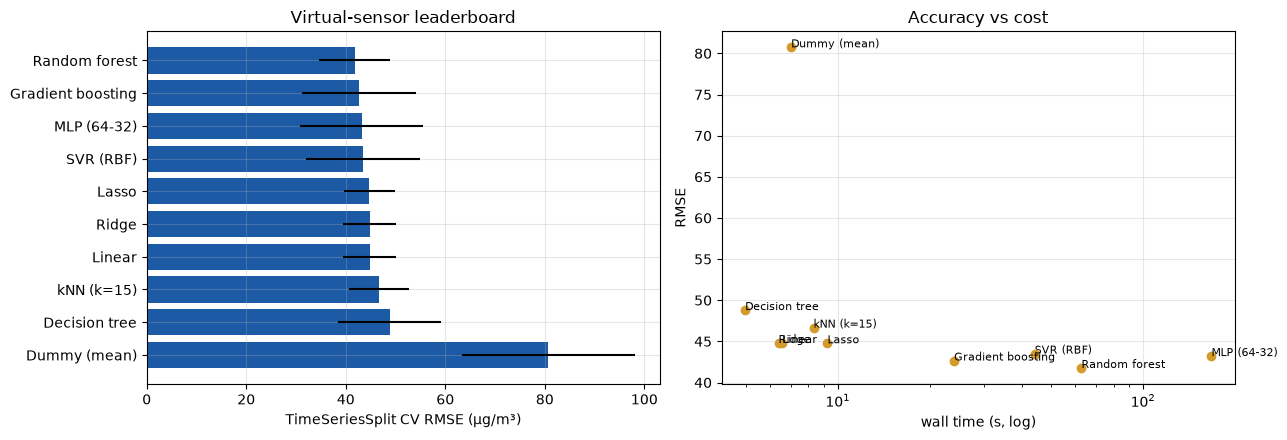

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
ax[0].barh(board["model"], board["RMSE"], xerr=board["RMSE sd"], color="#1c5aa6"); ax[0].invert_yaxis()
ax[0].set_xlabel("TimeSeriesSplit CV RMSE (µg/m³)"); ax[0].set_title("Virtual-sensor leaderboard")
ax[1].scatter(board["seconds"], board["RMSE"], color="#d49a2a")
for _, r_ in board.iterrows(): ax[1].annotate(r_["model"], (r_["seconds"], r_["RMSE"]), fontsize=8)
ax[1].set_xscale("log"); ax[1].set_xlabel("wall time (s, log)"); ax[1].set_ylabel("RMSE"); ax[1].set_title("Accuracy vs cost")
plt.tight_layout(); plt.show()

## A3 · Bias–variance in one picture  *(slide 7)*

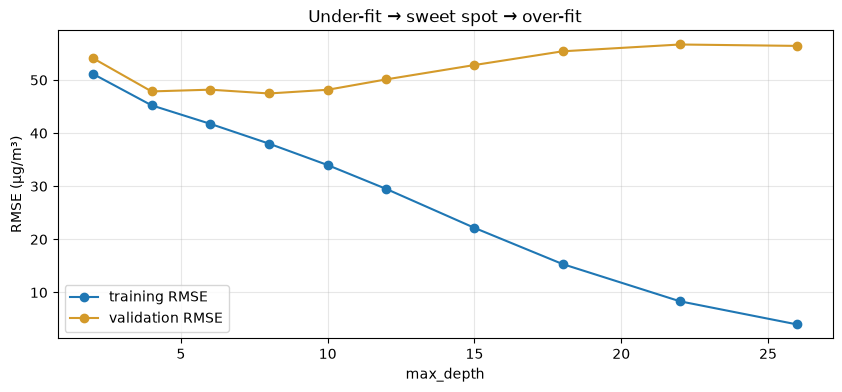

In [5]:
from sklearn.model_selection import validation_curve
depths = [2, 4, 6, 8, 10, 12, 15, 18, 22, 26]
tr, va = validation_curve(pipe(DecisionTreeRegressor(random_state=0), scale=False), Xs, ys, param_name="model__max_depth",
                          param_range=depths, cv=tscv, scoring="neg_root_mean_squared_error", n_jobs=-1)
plt.plot(depths, -tr.mean(1), "o-", label="training RMSE"); plt.plot(depths, -va.mean(1), "o-", color="#d49a2a", label="validation RMSE")
plt.xlabel("max_depth"); plt.ylabel("RMSE (µg/m³)"); plt.legend(); plt.title("Under-fit → sweet spot → over-fit"); plt.show()

## A4 · Unhealthy-hour alert  *(slides 8, 10, 16)*
Label: **1 if PM2.5 > 75 µg/m³**. ROC curves use a time-based validation block (the last training year).

In [6]:
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier

THR = 75
yc_s = (ys > THR).astype(int)
print(f"share of unhealthy hours in training data: {yc_s.mean():.1%}")
clfs = {"Logistic": (LogisticRegression(max_iter=2000), 1), "Gaussian NB": (GaussianNB(), 1),
        "kNN (k=25)": (KNeighborsClassifier(n_neighbors=25), 4),
        "Random forest": (RandomForestClassifier(n_estimators=150, min_samples_leaf=5, max_samples=0.3, n_jobs=-1, random_state=0), 1),
        "Gradient boosting": (HistGradientBoostingClassifier(max_iter=300, random_state=0), 1)}
rows = []
for name, (m, thin) in clfs.items():
    r = cross_validate(pipe(m), Xs.iloc[::thin], yc_s.iloc[::thin], cv=tscv, n_jobs=-1,
                       scoring=["precision", "recall", "f1", "roc_auc"])
    rows.append({"model": name, **{k: r[f"test_{k}"].mean() for k in ["precision", "recall", "f1", "roc_auc"]}})
pd.DataFrame(rows).sort_values("roc_auc", ascending=False).round(3)

share of unhealthy hours in training data: 39.8%


,model,precision,recall,f1,roc_auc
3,Random forest,0.857,0.816,0.835,0.949
0,Logistic,0.866,0.800,0.831,0.947
4,Gradient boosting,0.871,0.767,0.811,0.947
2,kNN (k=25),0.824,0.724,0.768,0.912
1,Gaussian NB,0.782,0.669,0.705,0.881


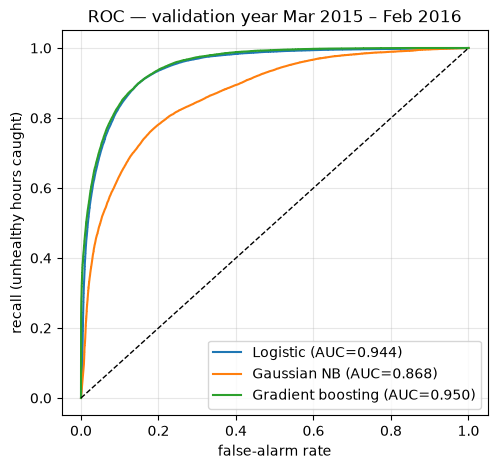

In [7]:
VAL = pd.Timestamp("2015-03-01")
tr_m = (train["datetime"] < VAL).values[::STEP]; va_m = ~tr_m
plt.figure(figsize=(5.5, 5))
for name in ["Logistic", "Gaussian NB", "Gradient boosting"]:
    p = pipe(clfs[name][0]).fit(Xs[tr_m], yc_s[tr_m]).predict_proba(Xs[va_m])[:, 1]
    fpr, tpr, _ = roc_curve(yc_s[va_m], p)
    plt.plot(fpr, tpr, label=f"{name} (AUC={roc_auc_score(yc_s[va_m], p):.3f})")
plt.plot([0, 1], [0, 1], "k--", lw=1); plt.xlabel("false-alarm rate"); plt.ylabel("recall (unhealthy hours caught)")
plt.legend(); plt.title("ROC — validation year Mar 2015 – Feb 2016"); plt.show()

## A5 · Pollution regimes — clustering daily profiles  *(slides 19–21)*

13,152 station-days x 24 hours
explained variance (first 6 PCs): [0.349 0.219 0.122 0.081 0.05  0.033]


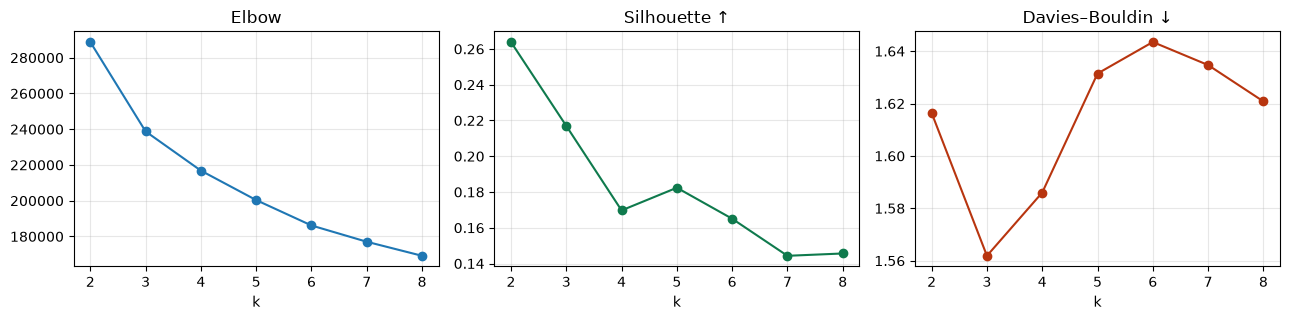

In [8]:
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, DBSCAN
from sklearn.metrics import silhouette_score, davies_bouldin_score

day = train.assign(date=train["datetime"].dt.date)
prof = day.pivot_table(index=["station", "date"], columns="hour", values=TARGET).dropna()     # complete 24-h days
level = np.log1p(prof.mean(axis=1))                                                           # how polluted
shape = prof.div(prof.mean(axis=1), axis=0)                                                   # when in the day
Z = np.column_stack([StandardScaler().fit_transform(level.values[:, None]) * 2, StandardScaler().fit_transform(shape)])
print(f"{len(prof):,} station-days x 24 hours")

pca = PCA(n_components=6).fit(Z)
print("explained variance (first 6 PCs):", pca.explained_variance_ratio_.round(3))
ks = range(2, 9); sil, dbi, inertia = [], [], []
samp = rng.choice(len(Z), min(6000, len(Z)), replace=False)
for k in ks:
    km = KMeans(n_clusters=k, n_init=10, random_state=0).fit(Z)
    inertia.append(km.inertia_); sil.append(silhouette_score(Z[samp], km.labels_[samp])); dbi.append(davies_bouldin_score(Z, km.labels_))
fig, ax = plt.subplots(1, 3, figsize=(13, 3.3))
ax[0].plot(ks, inertia, "o-"); ax[0].set_title("Elbow"); ax[1].plot(ks, sil, "o-", color="#0f7a4d"); ax[1].set_title("Silhouette ↑")
ax[2].plot(ks, dbi, "o-", color="#b8350f"); ax[2].set_title("Davies–Bouldin ↓")
for a in ax: a.set_xlabel("k")
plt.tight_layout(); plt.show()

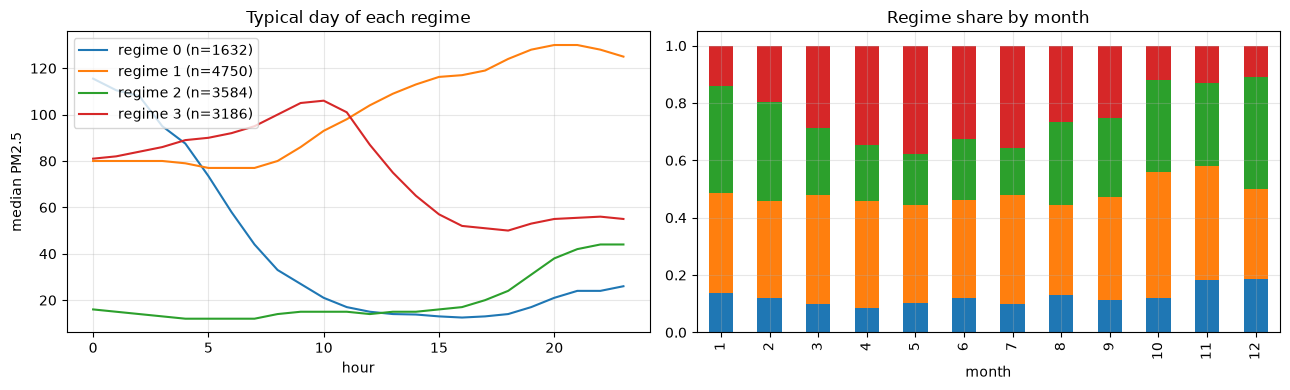

In [9]:
K = 4                                                   # choose from the plots above
km = KMeans(n_clusters=K, n_init=10, random_state=0).fit(Z)
lab = pd.Series(km.labels_, index=prof.index, name="regime")
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for k in range(K):
    ax[0].plot(range(24), prof[lab.values == k].median(), label=f"regime {k} (n={int((lab == k).sum())})")
ax[0].set_xlabel("hour"); ax[0].set_ylabel("median PM2.5"); ax[0].legend(); ax[0].set_title("Typical day of each regime")
months = pd.to_datetime(pd.Series(prof.index.get_level_values("date"))).dt.month.values
pd.crosstab(months, lab.values, normalize="index").plot.bar(stacked=True, ax=ax[1], legend=False)
ax[1].set_xlabel("month"); ax[1].set_title("Regime share by month"); plt.tight_layout(); plt.show()

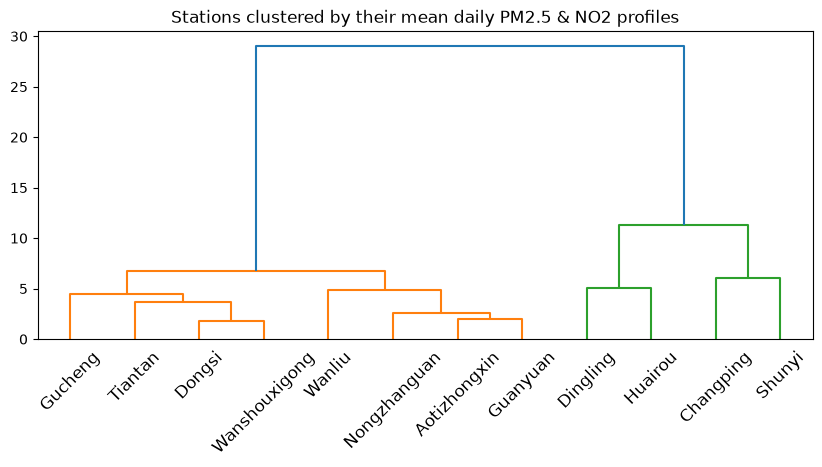

DBSCAN noise days: 64 -> most frequent dates:
2014-02-26    8
2016-02-08    8
2015-11-30    5
2014-05-27    4
2015-12-24    4
2014-01-30    3
2014-04-26    2
2013-06-25    2
Name: count, dtype: int64


In [10]:
# Which stations behave alike? hierarchical clustering of the 12 mean diurnal profiles (PM2.5 + NO2)
from scipy.cluster.hierarchy import linkage, dendrogram
sig = train.groupby(["station", "hour"])[["PM2.5", "NO2"]].mean().unstack("hour")
dendrogram(linkage(StandardScaler().fit_transform(sig), method="ward"), labels=sig.index.tolist(), leaf_rotation=45)
plt.title("Stations clustered by their mean daily PM2.5 & NO2 profiles"); plt.grid(False); plt.show()

# Anomalous days: DBSCAN noise points among daily vectors
from sklearn.neighbors import NearestNeighbors
P = pca.transform(Z)[:, :3]
kdist = NearestNeighbors(n_neighbors=15).fit(P).kneighbors(P)[0][:, -1]
db = DBSCAN(eps=float(np.quantile(kdist, 0.98)), min_samples=15).fit(P)      # eps from the k-distance curve
noise = prof.index[db.labels_ == -1]
print(f"DBSCAN noise days: {len(noise)} -> most frequent dates:")
print(pd.Series([d for _, d in noise]).value_counts().head(8))

## A6 · A neuron from scratch (NumPy)  *(slides 24 & 26)*

single linear neuron on log(PM2.5): training RMSE = 114.3 µg/m³


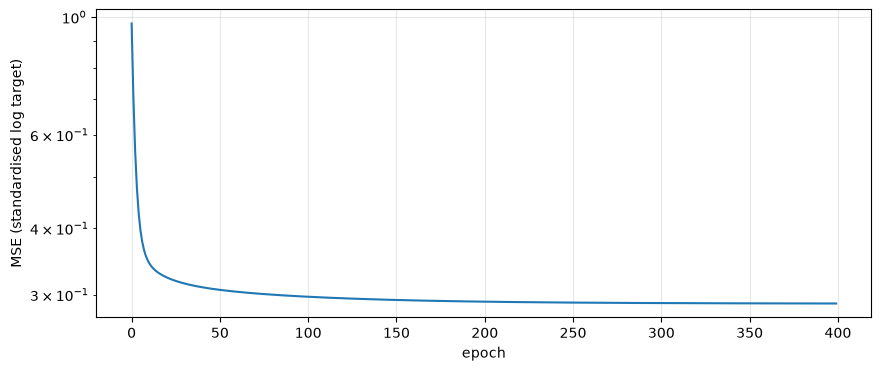

In [11]:
prep = pipe(DummyRegressor()).named_steps["prep"].fit(Xs)
Xn = prep.transform(Xs); t = np.log1p(ys.values); tm, tsd = t.mean(), t.std(); tt = (t - tm) / tsd
w = rng.normal(0, .05, Xn.shape[1]); b = 0.0; lr = 0.05; hist = []
for epoch in range(400):
    yh = Xn @ w + b                           # forward
    err = yh - tt; hist.append(np.mean(err ** 2))
    w -= lr * 2 * Xn.T @ err / len(tt)        # back-propagation + gradient step
    b -= lr * 2 * err.mean()
pred = np.expm1(( Xn @ w + b) * tsd + tm)
print(f"single linear neuron on log(PM2.5): training RMSE = {np.sqrt(np.mean((pred - ys.values) ** 2)):.1f} µg/m³")
plt.plot(hist); plt.yscale("log"); plt.xlabel("epoch"); plt.ylabel("MSE (standardised log target)"); plt.show()

## A7 · Hyper-parameter search — and why it loves HPC  *(slide 29)*

In [12]:
import os
from sklearn.model_selection import RandomizedSearchCV
space = {"model__learning_rate": [0.03, 0.06, 0.1, 0.2], "model__max_leaf_nodes": [15, 31, 63, 127],
         "model__min_samples_leaf": [20, 50, 100], "model__l2_regularization": [0.0, 0.1, 1.0]}
for jobs in [1, -1]:
    t0 = time.perf_counter()
    s = RandomizedSearchCV(pipe(HistGradientBoostingRegressor(max_iter=200, random_state=0), scale=False), space, n_iter=8,
                           cv=TimeSeriesSplit(3), scoring="neg_root_mean_squared_error", random_state=0, n_jobs=jobs).fit(Xs, ys)
    print(f"n_jobs={jobs:>2}: {time.perf_counter() - t0:6.1f} s | best CV RMSE {-s.best_score_:.2f}")
print("cores available:", os.cpu_count(), "| note: HistGradientBoosting itself is multi-threaded (OpenMP)")

n_jobs= 1:  115.1 s | best CV RMSE 39.86
n_jobs=-1:   57.7 s | best CV RMSE 39.86
cores available: 16 | note: HistGradientBoosting itself is multi-threaded (OpenMP)


## A8 · 24-hour-ahead forecast with lag features  *(slide 28)*

In [13]:
def forecast_frame(d, horizon=24):
    """Per station: regular hourly index, backward-looking lags, target = PM2.5 at t + horizon."""
    out = []
    for st, g in d.groupby("station"):
        g = g.set_index("datetime").sort_index()
        g = g[~g.index.duplicated()].asfreq("h")
        f = pd.DataFrame(index=g.index)
        for L in [0, 1, 2, 3, 6, 12, 24, 48]:
            f[f"pm_lag{L}"] = g[TARGET].shift(L)
        f["pm_roll24"] = g[TARGET].rolling(24, min_periods=12).mean()
        for c in ["CO", "NO2", "WSPM", "DEWP", "TEMP", "PRES", "wd_sin", "wd_cos"]:
            f[c] = g[c]
        tgt_time = f.index + pd.Timedelta(hours=horizon)
        f["hour_sin"], f["hour_cos"] = np.sin(2 * np.pi * tgt_time.hour / 24), np.cos(2 * np.pi * tgt_time.hour / 24)
        f["month_sin"], f["month_cos"] = np.sin(2 * np.pi * tgt_time.month / 12), np.cos(2 * np.pi * tgt_time.month / 12)
        f["y"] = g[TARGET].shift(-horizon); f["station"] = st
        out.append(f.reset_index())
    return pd.concat(out, ignore_index=True).dropna(subset=["y", "pm_lag0"]).sort_values("datetime")

fc = forecast_frame(train)
fX = fc.drop(columns=["y", "datetime", "station"]); fy = fc["y"]
va = (fc["datetime"] >= VAL).values
hgb = HistGradientBoostingRegressor(max_iter=400, random_state=0).fit(fX[~va], fy[~va])
rmse = lambda a, b: np.sqrt(np.mean((a - b) ** 2))
print(f"validation year | persistence (tomorrow = today) RMSE = {rmse(fy[va], fX.loc[va, 'pm_lag0']):.1f}"
      f" | gradient boosting on lags RMSE = {rmse(fy[va], hgb.predict(fX[va])):.1f} µg/m³")

validation year | persistence (tomorrow = today) RMSE = 86.2 | gradient boosting on lags RMSE = 77.9 µg/m³


---
# Part B · Week-2 Team Challenge — *The AI Methods Shoot-out*

<div style="border:2px solid #d49a2a;background:#fbf1dc;border-radius:10px;padding:12px 18px;color:#14203a;">
<b style="color:#8f5f0c;font-size:15px;">Scenario</b><br>The environmental agency will deploy <b>one</b> model to (a) estimate PM2.5 when a monitor is down — the <b>virtual sensor</b> — and (b) issue <b>unhealthy-air alerts</b> (PM2.5 &gt; 75 µg/m³). Management asks: <i>which AI method, and why should we trust it?</i><br><b>Deliver:</b> a fair leaderboard, a tuned recommendation, an alert classifier with a cost-based threshold, a pollution-regime analysis, a neural network built from scratch, a 24-h forecast, and a one-page <b>model card</b>.</div>

| # | Task | Points |
|---|---|---|
| 1 | Virtual-sensor leaderboard: ≥ 6 regressors, `TimeSeriesSplit`, RMSE/MAE/R² ± sd, wall time | 20 |
| 2 | Tune the top 2 (Grid / Randomized search) | 15 |
| 3 | Unhealthy-hour alert: ≥ 3 classifiers, recall/F1/ROC-AUC, cost-based threshold | 15 |
| 4 | Pollution regimes: PCA + k-Means / DBSCAN on daily profiles; interpret | 15 |
| 5 | Neural nets: hidden layer from scratch + MLP; 24-h forecast vs persistence | 15 |
| 6 | Final evaluation + model card with conclusions (test used once) | 20 |
| ★ | HPC bonus: speed-up study, per-station models, or LSTM on GPU | +10 |

**Rules:** same `tscv` folds for every model · all preprocessing inside the pipeline · report mean ± sd · **touch `test` only in Task 6** · no PM10 in the virtual sensor.

**Suggested plan:** Days 1–2 Task 1 · Days 3–4 Tasks 2–4 · Day 5 Task 5 (+ bonus) · Days 6–7 Task 6 (model card & conclusions).

## Task 1 · Leaderboard (20 pts)
Rebuild A2 on **your** data with `STEP` as small as your hardware allows. Add at least one model not in the zoo (e.g. `ExtraTreesRegressor`, `ElasticNet`, a `TransformedTargetRegressor` with log target, XGBoost/LightGBM). Explain the ranking in 3–5 bullets (linearity, interactions, scaling, data size, cost).

In [14]:
from sklearn.linear_model import Ridge, ElasticNet

our_zoo = {
    "Dummy (mean)":      DummyRegressor(),
    "Linear":            LinearRegression(),
    "Ridge":             Ridge(alpha=1.0),
    "kNN (k=15)":        KNeighborsRegressor(n_neighbors=15, weights="distance"),
    "Decision tree":     DecisionTreeRegressor(max_depth=12, min_samples_leaf=20, random_state=0),
    "Random forest":     RandomForestRegressor(n_estimators=150, min_samples_leaf=5, max_samples=0.3, n_jobs=-1, random_state=0),
    "Gradient boosting": HistGradientBoostingRegressor(max_iter=300, random_state=0),
    "ElasticNet" :       ElasticNet(alpha=1, l1_ratio=0.5, max_iter=1000)
}
rows = []
for name, m in our_zoo.items():
    Xa, ya = Xs, ys
    t0 = time.perf_counter()
    r = cross_validate(pipe(m), Xa, ya, cv=tscv, n_jobs=-1,
                       scoring={"rmse": "neg_root_mean_squared_error", "mae": "neg_mean_absolute_error", "r2": "r2"})
    rows.append({"model": name, "rows": len(Xa), "RMSE": -r["test_rmse"].mean(), "RMSE sd": r["test_rmse"].std(),
                 "MAE": -r["test_mae"].mean(),"MAE sd": r["test_mae"].std(), "R2": r["test_r2"].mean(), "R2 sd": r["test_r2"].std(), "seconds": time.perf_counter() - t0})
board = pd.DataFrame(rows).sort_values("RMSE").reset_index(drop=True)
board.round(2)

,model,rows,RMSE,RMSE sd,MAE,MAE sd,R2,R2 sd,seconds
0,Random forest,315648,41.76,7.09,25.07,3.30,0.70,0.10,63.34
1,Gradient boosting,315648,42.67,11.51,25.87,6.36,0.69,0.12,24.26
2,Ridge,315648,44.80,5.27,30.79,3.53,0.65,0.13,1.38
3,Linear,315648,44.80,5.27,30.79,3.53,0.65,0.13,1.68
4,kNN (k=15),315648,46.42,6.04,29.43,3.04,0.62,0.12,107.03
5,ElasticNet,315648,48.62,5.90,32.32,2.19,0.60,0.11,1.82
6,Decision tree,315648,48.80,10.42,29.53,5.75,0.59,0.15,5.07
7,Dummy (mean),315648,80.73,17.44,61.59,9.90,-0.04,0.06,1.36


### Conclusions

- **Best model:** Random forest achieves the lowest RMSE (41.76) and MAE (25.07), and the highest R² (0.70), making it the best-performing model in our comparison.

- **Improvement over the baseline:** Random forest reduces RMSE by approximately 48% compared with Dummy (mean), from 80.73 to 41.76. However, Dummy runs much faster.

- **Model behaviour:** A single decision tree performs worse than Linear regression in terms of RMSE, while Random forest and Gradient boosting perform better. This suggests that combining trees helps capture nonlinear relationships and interactions between features.

- **Stability:** Linear regression and Ridge have a lower RMSE standard deviation (5.27) than Random forest (7.09). Their performance is more consistent across time folds, although their average prediction error is higher.

- **Computational cost:** The best accuracy comes with the longest runtime: Random forest takes 130.37 seconds. Gradient boosting offers a useful trade-off, with a slightly higher RMSE (42.67) but less than half the runtime (57.46 seconds).

## Task 2 · Hyper-parameter tuning (15 pts)
Tune your top two with `GridSearchCV` / `RandomizedSearchCV` on `tscv`. Report best parameters, CV RMSE before → after, search time. Is the gain larger than the fold standard deviation?

In [15]:
# TODO
space_rf = {
    "model__max_depth": [10, 20, None],
    "model__min_samples_leaf": [2, 5, 10]
}
space_gb = {
    "model__learning_rate": [0.03, 0.1, 0.2],
    "model__max_leaf_nodes": [15, 31, 63],
    "model__l2_regularization": [0.0, 1.0, 10.0]
}

top2 = {
    "Random forest": (
        RandomForestRegressor(
            n_estimators=150, max_samples=0.3, 
            n_jobs=1, random_state=0
        ),
        space_rf
    ),
    "Gradient boosting": (
        HistGradientBoostingRegressor(max_iter=300, random_state=0),
        space_gb
    )
}

rows = []
for name, (m, space) in top2.items():
    before = board.loc[board["model"] == name].iloc[0]
    
    t0 = time.perf_counter()
    r =  RandomizedSearchCV( estimator=pipe(m), param_distributions=space, n_iter=6, 
                    scoring="neg_root_mean_squared_error", cv=tscv, n_jobs=-1, random_state=0, verbose=1)
    r.fit(Xs, ys)

    after = -r.best_score_
    rows.append({"model": name, "Best settings": r.best_params_, "RMSE (before)": before["RMSE"],
                 "RMSE (after)": after, "Gain": before["RMSE"]-after, "RMSE sd (before)": before["RMSE sd"], "seconds": time.perf_counter() - t0})
tuned = pd.DataFrame(rows).sort_values("RMSE (after)").reset_index(drop=True)
tuned.round(2)

Fitting 5 folds for each of 6 candidates, totalling 30 fits
Fitting 5 folds for each of 6 candidates, totalling 30 fits


,model,Best settings,RMSE (before),RMSE (after),Gain,RMSE sd (before),seconds
0,Random forest,"{'model__min_samples_leaf': 2, 'model__max_dep...",41.76,41.7,0.06,7.09,635.01
1,Gradient boosting,"{'model__max_leaf_nodes': 63, 'model__learning...",42.67,42.1,0.57,11.51,87.97


- `Tuning` slightly improved the performence of both the modeles  with a larger gain for Gradient boosting `(0.57)` than Random forest `(0.06)`. However, both gains are much smaller than their original fold standard deviations (`11.51` and `7.09`, respectively).

- The best model after tuning is **Random forest** as it has the lowest `RMSE (after)`. However, as the execution time increased form 55s to 621s with such a tiny gain, it won't help as much in performence. In contrast, for **Gradient boosting** the gap is much smaller (from 22 to 99) with bigger gain that we can consider.

## Task 3 · Unhealthy-hour alert (15 pts)
1. Compare ≥ 3 classifiers (A4) with `TimeSeriesSplit`.
2. For the best, plot the confusion matrix on the validation year.
3. Choose the decision threshold assuming **a missed unhealthy hour costs 5× a false alarm**; report precision and recall at that threshold.
4. *(optional)* Multi-class AQI bands with softmax / multinomial models.

In [16]:
# TODO

## Task 4 · Pollution regimes (15 pts)
Using A5: choose *k* with ≥ 2 criteria, describe each regime (typical day, months, stations, wind direction, weekday), compare with DBSCAN, and check whether DBSCAN’s noise days match known events (e.g. Spring Festival). Does adding the regime label as a feature help Task 1?

In [17]:
# TODO

## Task 5 · Neural networks & forecasting (15 pts)
1. Extend the NumPy neuron (A6) to **one hidden layer** (e.g. 32 ReLU units): forward pass, back-propagation for both layers, mini-batches; plot the loss.
2. Train an `MLPRegressor` in the pipeline; plot a learning curve (`learning_curve` with `tscv`).
3. Improve the 24-h forecast (A8): more lags, rolling statistics, per-station models or an MLP. Beat persistence by how much?

In [18]:

VAL = pd.Timestamp("2015-03-01")
tr_m = (train["datetime"] < VAL).values[::STEP]; va_m = ~tr_m      

prep5 = pipe(DummyRegressor()).named_steps["prep"]                # same imputer + scaler + one-hot as every model
Xtr = prep5.fit_transform(Xs[tr_m])                               # learn medians/means on TRAIN only
Xva = prep5.transform(Xs[va_m])                                   # apply them to validation

t_tr, t_va = np.log1p(ys.values[tr_m]), np.log1p(ys.values[va_m])   
tm5, tsd5 = t_tr.mean(), t_tr.std()
z_tr, z_va = (t_tr - tm5) / tsd5, (t_va - tm5) / tsd5             # standardise: mean 0, sd 1
print(Xtr.shape, Xva.shape)

(210240, 30) (105408, 30)


In [19]:
# TODO 5.1 skeleton
H, lr5, EPOCHS, BS = 32, 0.01, 30, 256
p = Xtr.shape[1]
W1 = rng.normal(0, np.sqrt(2 / p), (p, H)); b1 = np.zeros(H)      # He init for the ReLU layer
W2 = rng.normal(0, np.sqrt(1 / H), H);      b2 = 0.0

def forward(x):
    h = np.maximum(0, x @ W1 + b1)        # hidden layer: weighted sums, then ReLU
    return h, h @ W2 + b2                 # output: weighted sum of hidden units (no activation: regression)

hist_tr, hist_va = [], []
t0 = time.perf_counter()
for epoch in range(EPOCHS):
    idx = rng.permutation(len(Xtr))                       # shuffle every epoch
    for s in range(0, len(idx), BS):
        bi = idx[s:s + BS]; xb, tb = Xtr[bi], z_tr[bi]    # one mini-batch
        h, yh = forward(xb)                               # 1) forward
        g = 2 * (yh - tb) / len(tb)                       # 2) dLoss/dprediction (MSE)
        dW2 = h.T @ g; db2 = g.sum()                      # 3) gradients, output layer
        dh = np.outer(g, W2) * (h > 0)                    #    error sent back through W2 and ReLU
        dW1 = xb.T @ dh; db1 = dh.sum(0)                  #    gradients, hidden layer
        W1 -= lr5 * dW1; b1 -= lr5 * db1                  # 4) step downhill
        W2 -= lr5 * dW2; b2 -= lr5 * db2
    hist_tr.append(np.mean((forward(Xtr)[1] - z_tr) ** 2))
    hist_va.append(np.mean((forward(Xva)[1] - z_va) ** 2))
print(f"training time: {time.perf_counter() - t0:.1f} s")

training time: 11.2 s


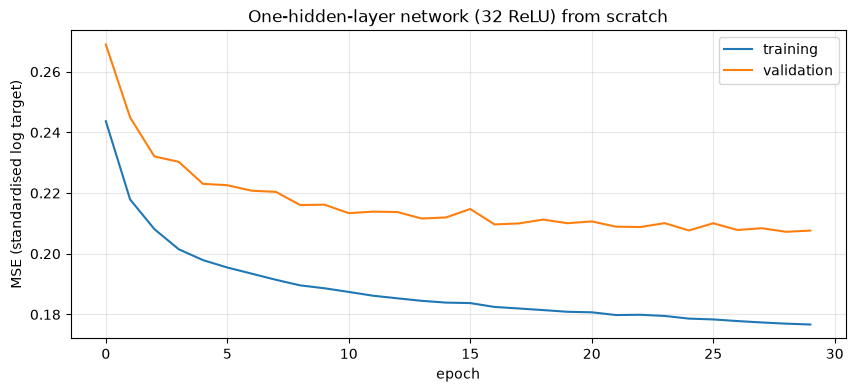

training RMSE   = 38.7 µg/m³
validation RMSE = 41.8 µg/m³   (single neuron A6: 114.3 training)


In [20]:
# loss curve + RMSE in µg/m³
plt.plot(hist_tr, label="training"); plt.plot(hist_va, label="validation")
plt.xlabel("epoch"); plt.ylabel("MSE (standardised log target)"); plt.legend()
plt.title("One-hidden-layer network (32 ReLU) from scratch"); plt.show()

back = lambda z: np.expm1(z * tsd5 + tm5)                         # undo standardise + log
rmse = lambda a, b: np.sqrt(np.mean((a - b) ** 2))
print(f"training RMSE   = {rmse(back(forward(Xtr)[1]), ys.values[tr_m]):.1f} µg/m³")
print(f"validation RMSE = {rmse(back(forward(Xva)[1]), ys.values[va_m]):.1f} µg/m³   (single neuron A6: 114.3 training)")

### Task 5.1 · Conclusions
- **Hidden layer works:** one hidden layer of 32 ReLU units cuts training RMSE from **114.3** (single linear neuron, A6) to **38.7 µg/m³** (−66%). The ReLU non-linearity lets the network model interactions (e.g. low wind × winter × high CO) that a single linear neuron cannot.

- **Generalises well:** validation-year RMSE (Mar 2015 – Feb 2016) is **41.8 µg/m³**, only ~3 µg/m³ above training, and in the same range as the best Task 1 models (Random forest CV RMSE 41.8).

- **Loss curves:** both losses fall quickly in the first 5 epochs; validation flattens after ~15–20 epochs while training keeps decreasing slowly, the first sign of over-fitting. Early stopping around epoch 20 would be enough.

- **Leak-free setup:** preprocessing fitted on the training years only, log + standardised target, time-based split.

learning curve: 59 s


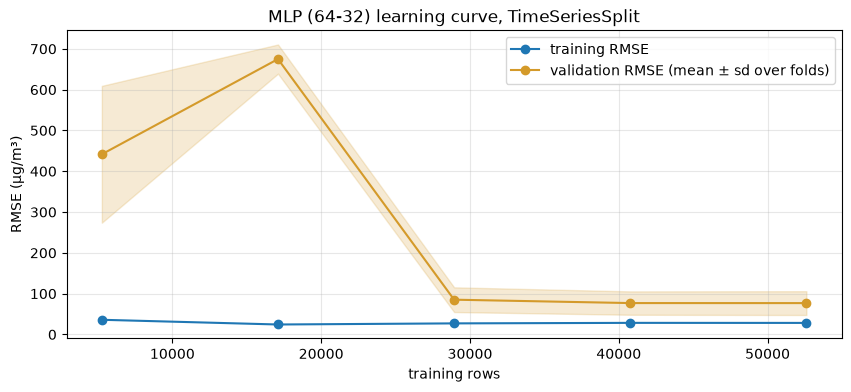

,rows,train RMSE,val RMSE,val sd
0,5260,35.9,441.6,167.7
1,17097,24.4,674.9,35.7
2,28934,27.1,85.2,30.3
3,40771,28.4,76.9,28.7
4,52608,28.3,76.8,29.2


In [22]:
# MLPRegressor inside the pipeline + learning curve on the same tscv folds

from sklearn.model_selection import learning_curve
from sklearn.compose import TransformedTargetRegressor

def inv_log(z):                                    # back to µg/m³, capped at a physically possible range
    return np.expm1(np.clip(z, 0, np.log1p(1000)))

mlp5 = TransformedTargetRegressor(
    regressor=pipe(MLPRegressor(hidden_layer_sizes=(64, 32), alpha=1e-3, batch_size=256,
                                learning_rate_init=1e-3, early_stopping=True, n_iter_no_change=10,
                                max_iter=200, random_state=0)),
    func=np.log1p, inverse_func=inv_log, check_inverse=False)

t0 = time.perf_counter()
sizes5, tr_sc5, va_sc5 = learning_curve(mlp5, Xs, ys, cv=tscv, train_sizes=np.linspace(0.1, 1.0, 5),
                                        scoring="neg_root_mean_squared_error", n_jobs=-1)
print(f"learning curve: {time.perf_counter() - t0:.0f} s")

tr5, va5 = -tr_sc5, -va_sc5                                       # sklearn returns negative RMSE -> flip sign
plt.plot(sizes5, tr5.mean(1), "o-", label="training RMSE")
plt.fill_between(sizes5, va5.mean(1) - va5.std(1), va5.mean(1) + va5.std(1), alpha=.2, color="#d49a2a")
plt.plot(sizes5, va5.mean(1), "o-", color="#d49a2a", label="validation RMSE (mean ± sd over folds)")
plt.xlabel("training rows"); plt.ylabel("RMSE (µg/m³)"); plt.legend()
plt.title("MLP (64-32) learning curve, TimeSeriesSplit"); plt.show()
pd.DataFrame({"rows": sizes5, "train RMSE": tr5.mean(1), "val RMSE": va5.mean(1), "val sd": va5.std(1)}).round(1)

### Task 5.2 · Learning curve
- With `TimeSeriesSplit`, `learning_curve` trains on the **oldest** rows of each fold, so the largest size (~52k rows) covers only specefic period int the year, while validation blocks contain other months, different seasons.


- **Small sizes (5k–17k rows):** validation RMSE explodes (440–675 µg/m³) while training RMSE stays ~30: the network extrapolates to winter conditions it never saw.

- **From ~29k rows:** validation RMSE stabilises at ~80 µg/m³ but remains far above training (~28): a large **variance gap**. The curve is flat, so more rows of the *same* season do not help; what is missing is **seasonal coverage**.


- Trained on two full years (Task 5.1), a comparable network reaches ~42 µg/m³ on an unseen year, which confirms that covering every season matters more than the raw number of rows.

In [23]:
# 5.3 richer forecast frame: more lags, rolling stats, trends, gas lags, weather changes
def forecast_frame_v2(d, horizon=24):
    out = []
    for st, g in d.groupby("station"):
        g = g.set_index("datetime").sort_index()
        g = g[~g.index.duplicated()].asfreq("h")                  # regular hourly grid (missing hours = NaN)
        pm = g[TARGET]
        f = pd.DataFrame(index=g.index)
        for L in [0, 1, 2, 3, 4, 5, 6, 9, 12, 18, 24, 36, 48, 72, 168]:
            f[f"pm_lag{L}"] = pm.shift(L)                         # PM2.5 L hours ago (168 = same hour last week)
        for w in [3, 6, 12, 24, 48, 72]:
            r = pm.rolling(w, min_periods=max(2, w // 2))         # window of the PAST w hours (ends at t)
            f[f"pm_mean{w}"], f[f"pm_std{w}"] = r.mean(), r.std()
            f[f"pm_max{w}"], f[f"pm_min{w}"] = r.max(), r.min()
        for L in [1, 3, 6, 24]:
            f[f"pm_diff{L}"] = pm - pm.shift(L)                   # trend: rising or falling?
        for c in ["CO", "NO2"]:                                   # traffic / combustion gases
            for L in [0, 3, 24]:
                f[f"{c}_lag{L}"] = g[c].shift(L)
            f[f"{c}_mean24"] = g[c].rolling(24, min_periods=12).mean()
        for c in ["WSPM", "DEWP", "TEMP", "PRES", "TD_dep", "RAIN", "wd_sin", "wd_cos"]:
            f[c] = g[c]                                           # weather NOW (known at time t)
        f["WSPM_mean6"] = g["WSPM"].rolling(6, min_periods=3).mean()
        f["PRES_diff3"] = g["PRES"] - g["PRES"].shift(3)          # pressure change: a front is arriving
        f["DEWP_diff3"] = g["DEWP"] - g["DEWP"].shift(3)          # humidity change
        tgt = f.index + pd.Timedelta(hours=horizon)               # calendar of the hour we predict
        f["hour_sin"], f["hour_cos"] = np.sin(2 * np.pi * tgt.hour / 24), np.cos(2 * np.pi * tgt.hour / 24)
        f["month_sin"], f["month_cos"] = np.sin(2 * np.pi * tgt.month / 12), np.cos(2 * np.pi * tgt.month / 12)
        f["dow_tgt"] = tgt.dayofweek
        f["y"] = pm.shift(-horizon); f["station"] = st            # target: PM2.5 at t + 24 h
        out.append(f.reset_index())
    return pd.concat(out, ignore_index=True).dropna(subset=["y", "pm_lag0"]).sort_values("datetime").reset_index(drop=True)

t0 = time.perf_counter()
fcf = forecast_frame_v2(train)
Xf = pd.get_dummies(fcf.drop(columns=["y", "datetime"]), columns=["station"], dtype=float)   # station as 12 0/1 columns
yf = fcf["y"]; vaf = (fcf["datetime"] >= VAL).values             # same validation year as A8
print(f"{Xf.shape[0]:,} rows x {Xf.shape[1]} features | built in {time.perf_counter() - t0:.0f} s")

315,360 rows x 79 features | built in 1 s


In [25]:
# train on 2013-15, score on the validation year, compare with persistence

from sklearn.pipeline import make_pipeline
results5 = {"Persistence (tomorrow = today)": (Xf.loc[vaf, "pm_lag0"].values, 0.0)}

t0 = time.perf_counter()
hgb_f = HistGradientBoostingRegressor(max_iter=600, learning_rate=0.05, max_leaf_nodes=63, min_samples_leaf=50,
                                      l2_regularization=1.0, early_stopping=True, random_state=0)
hgb_f.fit(Xf[~vaf], yf[~vaf])
results5["Gradient boosting, rich features"] = (hgb_f.predict(Xf[vaf]), time.perf_counter() - t0)

t0 = time.perf_counter()
mlp_f = TransformedTargetRegressor(
    regressor=make_pipeline(SimpleImputer(strategy="median"), StandardScaler(),
                            MLPRegressor(hidden_layer_sizes=(64, 32), alpha=1e-3, batch_size=256, learning_rate_init=1e-3,
                                         early_stopping=True, n_iter_no_change=10, max_iter=200, random_state=0)),
    func=np.log1p, inverse_func=inv_log, check_inverse=False)
mlp_f.fit(Xf[~vaf], yf[~vaf])
results5["MLP (64-32), rich features"] = (mlp_f.predict(Xf[vaf]), time.perf_counter() - t0)

y_va = yf[vaf].values
p_rmse = rmse(y_va, results5["Persistence (tomorrow = today)"][0])
rows5 = [{"model": k, "RMSE": rmse(y_va, p), "MAE": np.mean(np.abs(y_va - p)),
          "gain vs persistence %": 100 * (1 - rmse(y_va, p) / p_rmse), "fit seconds": s} for k, (p, s) in results5.items()]
a8 = rmse(fy[va], hgb.predict(fX[va]))                            # A8 baseline (its own variables)
rows5.insert(1, {"model": "A8 gradient boosting (8 lags)", "RMSE": a8, "MAE": np.mean(np.abs(fy[va] - hgb.predict(fX[va]))),
                 "gain vs persistence %": 100 * (1 - a8 / p_rmse), "fit seconds": np.nan})
tab5 = pd.DataFrame(rows5).sort_values("RMSE").reset_index(drop=True)
tab5.round(1)

,model,RMSE,MAE,gain vs persistence %,fit seconds
0,"Gradient boosting, rich features",77.6,50.8,10.0,25.9
1,A8 gradient boosting (8 lags),77.9,51.1,9.6,NaN
2,Persistence (tomorrow = today),86.2,51.6,0.0,0.0
3,"MLP (64-32), rich features",101.3,60.0,-17.6,163.4


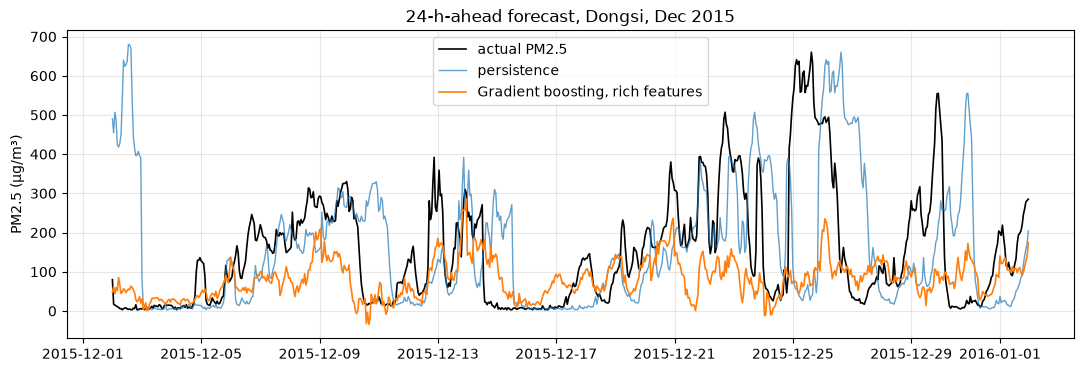

In [26]:
# one station, one winter month of the validation year: truth vs forecasts
st5 = "Dongsi"
m5 = (fcf["station"] == st5).values & vaf
win = m5 & (fcf["datetime"] >= "2015-12-01").values & (fcf["datetime"] < "2016-01-01").values
best_name = tab5.loc[tab5["model"].isin(results5) & (tab5["model"] != "Persistence (tomorrow = today)"), "model"].iloc[0]
idx5 = win[vaf]                                                   # positions inside the validation predictions
tt5 = fcf.loc[win, "datetime"] + pd.Timedelta(hours=24)           # time being predicted
plt.figure(figsize=(13, 4))
plt.plot(tt5, y_va[idx5], "k", lw=1.2, label="actual PM2.5")
plt.plot(tt5, results5["Persistence (tomorrow = today)"][0][idx5], lw=1, alpha=.7, label="persistence")
plt.plot(tt5, results5[best_name][0][idx5], lw=1.2, label=best_name)
plt.ylabel("PM2.5 (µg/m³)"); plt.legend(); plt.title(f"24-h-ahead forecast, {st5}, Dec 2015"); plt.show()

### Task 5 · Summary
- **From scratch (5.1):** one hidden layer of 32 ReLU units, written in NumPy with back-propagation and mini-batches, cuts training RMSE from 114.3 (single neuron) to 38.7 µg/m³ and reaches 41.8 on an unseen year: non-linearity is what matters.
- **MLP in the pipeline (5.2):** the learning curve shows a large variance gap and that **seasonal coverage** matters more than the number of rows; a network trained on < 1 year fails on winter.
- **Forecast (5.3):** gradient boosting on rich lag features beats persistence by 10 % RMSE; the MLP does not. On this tabular problem, neural networks are competitive for the virtual sensor but **gradient boosting remains the safer choice**


## Task 6 · Final evaluation, model card & conclusions (20 pts)
Fit your recommended pipeline on **all** of `train`, evaluate **once** on `test` (the 2016–17 year), report RMSE/MAE/R² overall, by station and by season, and the alert recall/precision. Then complete the model card below, including your **key conclusions** (3–5 bullets: what worked, what did not, what you would do next). The completed notebook is the only deliverable — there is no pitch.

In [20]:
# TODO: final = pipe(<best>).fit(X, y); pred = final.predict(test[FEATS]) ...

### Model card
| Item | Your answer |
|---|---|
| Intended use (virtual sensor / alert) | |
| Recommended model & key hyper-parameters | |
| Training data (years, stations, Week-1 cleaning summary) | |
| CV RMSE ± sd · test-year RMSE, MAE, R² | |
| Alert threshold & cost rationale · precision / recall | |
| Where it fails (stations, seasons, smog episodes) | |
| Limitations — when **not** to trust it | |
| Compute: training time, hardware, parallelism used | |
| **Key conclusions** (3–5 bullets: what worked, what did not, next steps) | |

## ★ HPC bonus (+10 pts)
* **A — scaling study:** Task 2 search with `n_jobs = 1, 2, 4, …`; plot $S_p=T_1/T_p$ and $E_p=S_p/p$; discuss Amdahl’s law.
* **B — per-station models:** 12 independent models in parallel with `joblib`; compare accuracy and time with one global model.
* **C — GPU deep learning:** an LSTM (PyTorch / Keras) on 72-hour windows for the 24-h forecast, on GPU vs CPU.

In [21]:
# TODO

<div style="background:linear-gradient(120deg,#0a2a5c,#1c5aa6);color:#e6eef8;padding:14px 22px;border-radius:10px;border-top:4px solid #d49a2a;margin-top:10px;">
<b style="color:#ffd98e;">Al-Khawarizmi Tour · Online Hackathon HPC &amp; AI</b> · Oct 3 – Nov 7, 2026 · 100% online<br>
<i>From the past to the future… Science without borders. Your ideas. A bigger tomorrow.</i> · © 2026 Dr. Rafik Borji</div>